# **STEP 4, PART 1.6**

### **How non-axisymmetric is LAB itself, and how wide is data - model?**

Before $\sigma$ is considered for the Bayesian step, we wish to look at the width of two residual distributions. The idea for quantifying this comes from Marasco+19: the mirrored hemisphere is an empirical measure of what an axisymmetric model cannot be expected to reproduce.

1. **LAB north - south:** For every voxel $(l, |b|, v)$ with data in both hemispheres, $D(l, +b, v) - D(l, -b, v)$. A pair is kept only if both members exist outside of every mask (disk, outer arm, GCP, external galaxies, Magellanic region, coverage).
2. **Data - model:** On the full sky, for the best symmetric and asymmetric models (one flux scale, as in the grid searches).

If the two hemispheres were independent draws around one axisymmetric sky with scatter $s$ per voxel, then $\mathrm{sd}(D_N - D_S) = \sqrt 2\, s$. The quantity $s_{NS} = \mathrm{sd}(D_N - D_S)/\sqrt 2$ is therefore the scatter that *no axisymmetric model can remove* (clumps, complexes, noise, etc.).

For a symmetric model, the residual splits exactly into a common part $r_{\rm sym} = (r_N + r_S)/2$ and an antisymmetric part $r_{\rm anti} = (r_N - r_S)/2 = (D_N - D_S)/2$, which is the same for every symmetric model. An asymmetric model can lower the antisymmetric part by its own north-south contrast.

*Two caveats:* These are widths of *residuals* (a scale for $\sigma$), not a likelihood, and the voxels are correlated due to binning, which is a separate matter (the $N_{\rm eff}$ of the diagnostics notebook). Histograms alos count every voxel once (no $\cos b$ weight).

| section | what it looks for |
|---|---|
| 0. Settings | paths, the comparison with LAB (as in the other notebooks) |
| 1. LAB north - south | pairs, histogram, tails, brightness law $\sigma(L)$, where the width sits |
| 2. Data - model | histograms per hemisphere, the split into common and antisymmetric parts, the same law |
| 3. What $\sigma$ to expect | the numbers side by side |
| 4. Further checks | widths binned like for like, tails after standardizing, and the estimator of Marasco+19 |

## 0. Settings

In [1]:
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.optimize import nnls

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

LAB_PATH = "../Displays/lab.fit.gz"
PRODUCTS = "../Convergence/lab_products.npz"
GRID     = Path("../Convergence/grid")
PLOT     = Path("./plots")

# ---------------- the comparison with LAB: the same settings as the grid searches ----------------
B_CUT, L_CUT = 0, 0
V_DEV      = 35.0
REL_FLOOR  = 0.04
B_MIN      = 0.0

# ---------------- the best-fit models from grid-searches ----------------
MODELS = {
    "symmetric":                    ("best_model", Path("../Grid_Search/")),    # G1 best model
    "asymmetric (v_motion = -55)":  ("best_both", Path("./")),                  # B1 best model
}
SAVE_JSON = Path("./residual_distributions.json")

In [2]:
from mw_io import load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions, flat_v_circ,
                     OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)
from marasco_comp import *

def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH, correction=False)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, 
                        CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0), rel_floor=REL_FLOOR)

SIGMA = float(P.sigma_empty)                      # K, noise of one voxel of the comparison grid (empty channels)
D3 = np.asarray(cmp.lab_cmp.data, float)          # (nv, nb, nl); NaN where masked or without coverage
bgrid, lgrid, vgrid = (np.asarray(a, float) for a in (cmp.b, cmp.l, cmp.v))

D3[:, bgrid == 0, :] = np.nan                     # the b = 0 row has no partner
jm = np.argmin(np.abs(bgrid[:, None] + bgrid[None, :]), axis=1)          # the row of -b for every row b
has_partner = np.isclose(bgrid[jm], -bgrid) & (bgrid != 0)
iN = np.where((bgrid > B_MIN) & has_partner)[0]                          # northern rows with a southern partner row
iS = jm[iN]
shp = (len(vgrid), len(iN), len(lgrid))

print(f"Comparison grid: {len(vgrid)} v x {len(bgrid)} b x {len(lgrid)} l\n"
      f"{int(np.isfinite(D3).sum())} LAB voxels with data; noise of one voxel {1e3 * SIGMA:.2f} mK\n"
      f"{len(iN)} pairs of rows (+b, -b) with |b| > {B_MIN:g} deg: |b| = {bgrid[iN].min():g} ... {bgrid[iN].max():g}")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: none
Note: correction=False, the stored correction is NOT applied; the stored sigma belongs to the corrected cube.
Comparison grid: 62 v x 41 b x 90 l
160448 LAB voxels with data; noise of one voxel 3.12 mK
20 pairs of rows (+b, -b) with |b| > 0 deg: |b| = 4 ... 80


## 1. LAB north - south

A pair $(l, +b, v)$ / $(l, -b, v)$ is kept if both voxels are valid. Every mask (the disk envelope, the outer arm, the Galactic-centre region, the external galaxies, the Magellanic box, the coverage cut) removes a voxel from the pair as a whole, so a region masked in one hemisphere is absent from the other as well. The first cell counts what that does to the data.

The histograms show $D_N - D_S$ in mK: the left panel zooms into the core (to $\pm 6$ robust $\sigma$), the right one shows everything on a logarithmic axis. What is overlaid are a Gaussian with the robus width (1.4826 MAD), the pure instrument noise $\sqrt 2\,\sigma_{\rm noise}$, and a Student-$t$ distribution.

Valid voxels with a partner row: north 84975, south 75473
Kept as pairs: 71680 pairs = 89.3 % of those voxels
> dropped from the north because the south voxel is masked or has no coverage: 13295 (15.6 % of the northern ones)
> dropped from the south because the north voxel is masked or has no coverage: 3793 (5.0 % of the southern ones)
                              n    mean  median      sd  robust   68%/2  ex.kurt   >3 rob    >5 rob
D_N - D_S                 71680   16.46   -0.64  131.51    7.30    8.07   105.05   11.94%   8.7207%
(D_N - D_S) / sqrt 2      71680   11.64   -0.45   92.99    5.16    5.70   105.05   11.94%   8.7207%
(mK.  Gaussian: excess kurtosis 0, 0.27 % beyond 3 robust sigma, 0.00006 % beyond 5.)

Instrument noise alone would give sd(N - S) = 4.42 mK  ->  LAB's robust N-S width is 1.7 times that, the rms 29.8 times.
Student-t fit of N - S: nu = 0.99, location -1.08 mK, scale 4.76 mK


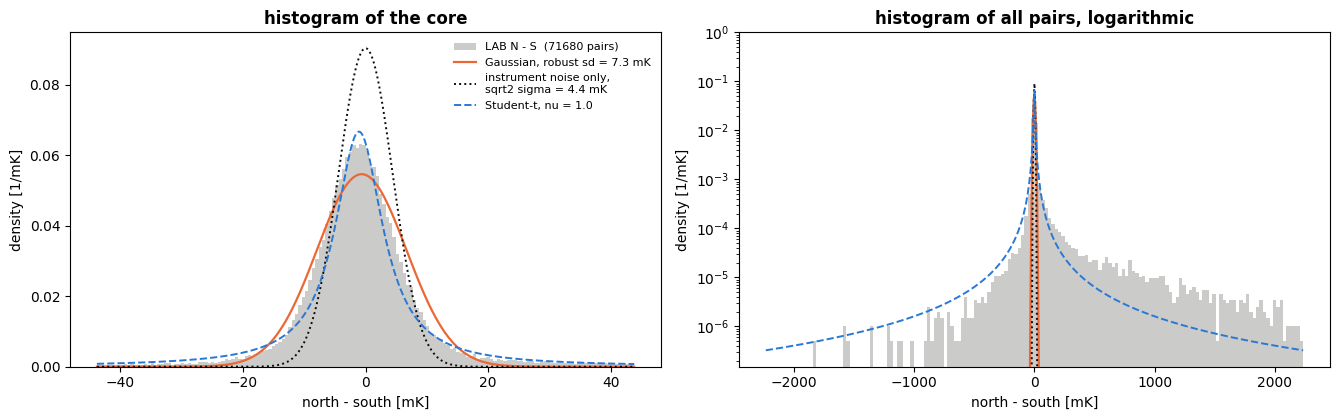

In [3]:
DN, DS = D3[:, iN, :], D3[:, iS, :]
PAIR = np.isfinite(DN) & np.isfinite(DS)

nN, nS = int(np.isfinite(DN).sum()), int(np.isfinite(DS).sum())
print(f"Valid voxels with a partner row: north {nN}, south {nS}")
print(f"Kept as pairs: {int(PAIR.sum())} pairs = {200 * PAIR.sum() / (nN + nS):.1f} % of those voxels")
print("> dropped from the north because the south voxel is masked or has no coverage: "
      f"{nN - int(PAIR.sum())} ({100 * (nN - PAIR.sum()) / nN:.1f} % of the northern ones)")
print("> dropped from the south because the north voxel is masked or has no coverage: "
      f"{nS - int(PAIR.sum())} ({100 * (nS - PAIR.sum()) / nS:.1f} % of the southern ones)")

BA = np.broadcast_to(bgrid[iN][None, :, None], shp)
VV = np.broadcast_to(vgrid[:, None, None], shp)
LL = np.broadcast_to(((lgrid + 180.0) % 360.0 - 180.0)[None, None, :], shp)
b_p, v_p, l_p = BA[PAIR], VV[PAIR], LL[PAIR]

NS   = 1e3 * (DN - DS)[PAIR]                  # mK: north minus south
LEV  = 0.5 * (DN + DS)[PAIR]                  # K: the mean of the pair, a model-free estimate of the symmetric sky
NOISE_NS = np.sqrt(2.0) * 1e3 * SIGMA         # mK: sd of N - S if only the instrument noise were left

def describe(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    med = float(np.median(x))
    rob = 1.4826 * float(np.median(np.abs(x - med)))
    p16, p84 = np.percentile(x, [16, 84])
    return dict(n=int(x.size), 
                mean=float(x.mean()), 
                median=med, 
                sd=float(x.std()), 
                rob=rob, 
                half68=0.5 * float(p84 - p16),
                kurt=float(stats.kurtosis(x)), 
                t3=float(np.mean(np.abs(x - med) > 3 * rob)), 
                t5=float(np.mean(np.abs(x - med) > 5 * rob)))

def show_table(rows):
    print(f"{'':22s} {'n':>8s} {'mean':>7s} {'median':>7s} {'sd':>7s} {'robust':>7s} {'68%/2':>7s} "
          f"{'ex.kurt':>8s} {'>3 rob':>8s} {'>5 rob':>9s}")
    for lab_, d in rows:
        print(f"{lab_:22s} {d['n']:8d} {d['mean']:7.2f} {d['median']:7.2f} {d['sd']:7.2f} {d['rob']:7.2f} "
              f"{d['half68']:7.2f} {d['kurt']:8.2f} {100 * d['t3']:7.2f}% {100 * d['t5']:8.4f}%")
    print("(mK.  Gaussian: excess kurtosis 0, 0.27 % beyond 3 robust sigma, 0.00006 % beyond 5.)")

dNS = describe(NS)
show_table([("D_N - D_S", dNS), ("(D_N - D_S) / sqrt 2", describe(NS / np.sqrt(2.0)))])
print(f"\nInstrument noise alone would give sd(N - S) = {NOISE_NS:.2f} mK  ->  "
      f"LAB's robust N-S width is {dNS['rob'] / NOISE_NS:.1f} times that, the rms {dNS['sd'] / NOISE_NS:.1f} times.")

rng = np.random.default_rng(3)
sub = NS if NS.size <= 40000 else rng.choice(NS, 40000, replace=False)
nu_t, loc_t, sc_t = stats.t.fit(sub)
print(f"Student-t fit of N - S: nu = {nu_t:.2f}, location {loc_t:.2f} mK, scale {sc_t:.2f} mK")

def gauss(x, mu, sd): return np.exp(-0.5 * ((x - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi))

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.3))
for ax, X, logy in ((axs[0], 6 * dNS["rob"], False), (axs[1], float(np.percentile(np.abs(NS), 99.99)), True)):
    bins = np.linspace(-X, X, 161); xx = np.linspace(-X, X, 801)
    ax.hist(NS, bins=bins, density=True, 
            color="#8d8c88", alpha=0.45, label=f"LAB N - S  ({NS.size} pairs)")
    ax.plot(xx, gauss(xx, dNS["median"], dNS["rob"]), "-", 
            color="#eb6834", lw=1.6, label=f"Gaussian, robust sd = {dNS['rob']:.1f} mK")
    ax.plot(xx, gauss(xx, 0.0, NOISE_NS), ":", 
            color="#0b0b0b", lw=1.4, label=f"instrument noise only,\nsqrt2 sigma = {NOISE_NS:.1f} mK")
    ax.plot(xx, stats.t.pdf(xx, nu_t, loc_t, sc_t), "--", 
            color="#2a78d6", lw=1.4, label=f"Student-t, nu = {nu_t:.1f}")
    if logy: 
        ax.set_yscale("log"); 
        ax.set_ylim((0.3 / (NS.size * (bins[1] - bins[0])), 1))

    ax.set(xlabel="north - south [mK]", ylabel="density [1/mK]")
    ax.set_title("histogram of the core" if not logy else "histogram of all pairs, logarithmic", weight="bold")
axs[0].legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(PLOT / "residual_NS_hist.png", dpi=150)
plt.show()

### 1.1 Does the width grow with the brightness, and where does it sit?

The pairs are binned by their mean brightness $L = (D_N + D_S)/2$ (for pure Gaussian noise $L$ and $D_N - D_S$ are independent, so the binning does not bias the width). In each bin, the width of $(D_N - D_S)/\sqrt 2$ is measured, and the law used in the likelihoods of the previous notebooks, $\sigma^2(L) = \sigma_0^2 + \epsilon^2 L^2$, is fitted to the rms of the bins with the weights of the diagnostics notebook (every bin counts by $\sqrt n$ of its relative error). The second figure shows the width against $|b|$, $v$ and $l$.

   L [mK]    pairs      rms   robust   (width of (D_N - D_S)/sqrt2, mK)
      0.4     9517      4.0      3.6
      2.4     6358      4.1      3.7
      4.7    14450      4.0      3.8
      8.9    16896      4.8      4.3
     17.2    13764      7.7      6.2
     34.6     4685     21.9     21.3
     69.4     2625     53.3     51.7
    139.6     1434    119.7     94.5
    288.1      852    258.8    190.8
    567.7      818    539.6    314.9
   1014.7      281   1037.3    439.0
Law fitted to the rms: sigma0 =   3.7 mK (noise 3.1),  eps = 0.405
Law fitted to the rob: sigma0 =   3.5 mK (noise 3.1),  eps = 0.325


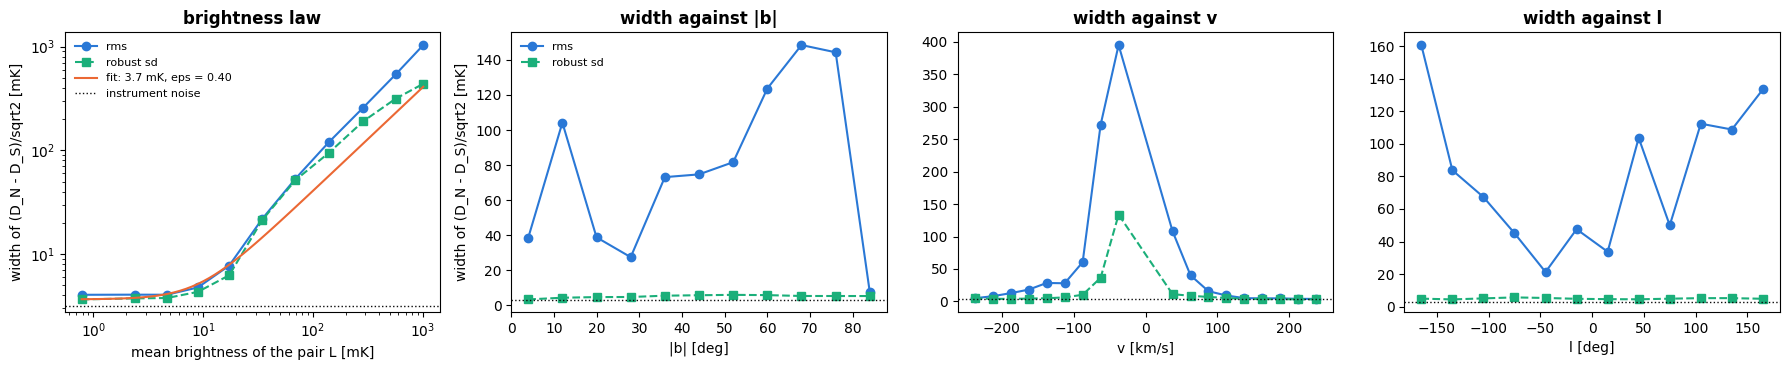

In [4]:
def level_rows(level, s, edges, min_n=30):
    """ rms and robust sd of s in bins of level. """
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        q = (level >= lo) & (level < hi)

        if q.sum() < min_n: 
            continue

        x = s[q]
        med = np.median(x)
        rows.append(dict(m=float(level[q].mean()), 
                         n=int(q.sum()), 
                         rms=float(np.sqrt(np.mean(x ** 2))), 
                         rob=float(1.4826 * np.median(np.abs(x - med)))))
    return rows

def fit_law(rows, key="rms"):
    """ sigma0, eps of sigma^2 = sigma0^2 + eps^2 L^2. """
    A = np.array([[1.0, r["m"] ** 2] for r in rows])
    y = np.array([r[key] ** 2 for r in rows])
    wgt = np.sqrt([r["n"] for r in rows])

    coef, _ = nnls(A * wgt[:, None] / y[:, None], wgt)
    return float(np.sqrt(coef[0])), float(np.sqrt(coef[1]))

# The edges are in K, from sigma/2 up in factors of two (the lowest bin starts at 0).
EDGES = np.concatenate([[0.0], SIGMA * 2.0 ** np.arange(-1, 9), [np.inf]])
S_NS = NS / np.sqrt(2.0) * 1e-3                                             # K: (D_N - D_S) / sqrt 2
ROWS_NS = level_rows(np.clip(LEV, 0.0, None), S_NS, EDGES)
LAW_NS = {k: fit_law(ROWS_NS, k) for k in ("rms", "rob")}
print(f"{'L [mK]':>9s} {'pairs':>8s} {'rms':>8s} {'robust':>8s}   (width of (D_N - D_S)/sqrt2, mK)")

for r in ROWS_NS: 
    print(f"{1e3 * r['m']:9.1f} {r['n']:8d} {1e3 * r['rms']:8.1f} {1e3 * r['rob']:8.1f}")
for k, (a0, eps) in LAW_NS.items():
    print(f"Law fitted to the {k:3s}: sigma0 = {1e3 * a0:5.1f} mK (noise {1e3 * SIGMA:.1f}),  eps = {eps:.3f}")

def group_rows(key, s, edges, min_n=30):
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        q = (key >= lo) & (key < hi)
        if q.sum() < min_n: continue
        x = s[q]
        out.append((0.5 * (lo + hi), 
                    1e3 * np.sqrt(np.mean(x ** 2)), 
                    1e3 * 1.4826 * np.median(np.abs(x - np.median(x))), 
                    int(q.sum())))
        
    return np.array(out)

fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
mm = np.array([max(r["m"], 0.25 * SIGMA) for r in ROWS_NS])
axs[0].loglog(1e3 * mm, [1e3 * r["rms"] for r in ROWS_NS], "o-", color="#2a78d6", label="rms")
axs[0].loglog(1e3 * mm, [1e3 * r["rob"] for r in ROWS_NS], "s--", color="#1baf7a", label="robust sd")

mg = np.geomspace(mm.min(), mm.max(), 60); a0, eps = LAW_NS["rms"]
axs[0].loglog(1e3 * mg, 1e3 * np.sqrt(a0 ** 2 + (eps * mg) ** 2), "-", color="#eb6834", 
              label=f"fit: {1e3 * a0:.1f} mK, eps = {eps:.2f}")
axs[0].axhline(1e3 * SIGMA, color="#0b0b0b", ls=":", lw=1, label="instrument noise")
axs[0].set(xlabel="mean brightness of the pair L [mK]", ylabel="width of (D_N - D_S)/sqrt2 [mK]")
axs[0].set_title("brightness law", weight="bold")
axs[0].legend(frameon=False, fontsize=8)

for ax, key, edges, name in ((axs[1], b_p, np.arange(0, 89, 8.0), "|b| [deg]"),
                             (axs[2], v_p, np.arange(-250, 251, 25.0), "v [km/s]"),
                             (axs[3], l_p, np.arange(-180, 181, 30.0), "l [deg]")):
    g_ = group_rows(key, S_NS, edges)
    ax.plot(g_[:, 0], g_[:, 1], "o-", color="#2a78d6", label="rms")
    ax.plot(g_[:, 0], g_[:, 2], "s--", color="#1baf7a", label="robust sd")
    ax.axhline(1e3 * SIGMA, color="#0b0b0b", ls=":", lw=1)
    ax.set_xlabel(name)
    ax.set_title(f"width against {name.split()[0]}", weight="bold")
axs[1].set_ylabel("width of (D_N - D_S)/sqrt2 [mK]")
axs[1].legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(PLOT / "residual_NS_where.png", dpi=150)
plt.show()

## 2. Data - model on the full sky

For each model of the settings: the model is put on the comparison grid like in the grid searches (`cmp.model_cmp`; its own masks), scaled by one factor, $\sum w D / \sum w M$ over the valid voxels, which is the factor `evaluate` uses, and subtracted from LAB. A voxel is *valid* if data and model are finite there and $b \neq 0$.

### 2.1 Histograms

Per model: the residual $D - M$ of the whole valid sky (all voxels) and of the north and the south on their own, against the reference $(D_N - D_S)/\sqrt 2$ of section 1 (grey). The table lists the same numbers as in section 1. The last rows of each block use only the voxels whose mirror partner is valid in data **and** model, i.e., the very pairs of section 2.2 (so that the widths are compared on identical voxels).

symmetric                                  best_model: scale 0.1581, 160304 valid voxels
asymmetric (v_motion = -55)                best_both: scale 87.5851, 160304 valid voxels

Symmetric (pairs valid in data and model: 71572)
                              n    mean  median      sd  robust   68%/2  ex.kurt   >3 rob    >5 rob
D - M, all valid voxels   160304    2.83    2.50  141.03    8.34   11.48   338.11   16.35%  11.0191%
D - M, north              84941   13.04    1.74  156.35    8.31   11.13   224.33   16.26%  10.5026%
D - M, south              75363   -8.68    3.39  120.45    8.03   12.08   626.04   16.75%  11.9953%
D - M, voxels of the pairs (N and S together)   143144    5.45    3.12  128.14    7.68    9.29   454.73   14.85%  10.0766%
(D_N - D_S)/sqrt2, the same pairs    71572   11.62   -0.45   92.92    5.16    5.70   105.48   11.89%   8.6822%
(mK.  Gaussian: excess kurtosis 0, 0.27 % beyond 3 robust sigma, 0.00006 % beyond 5.)

Asymmetric (v_motion = -55) (pairs valid in data a

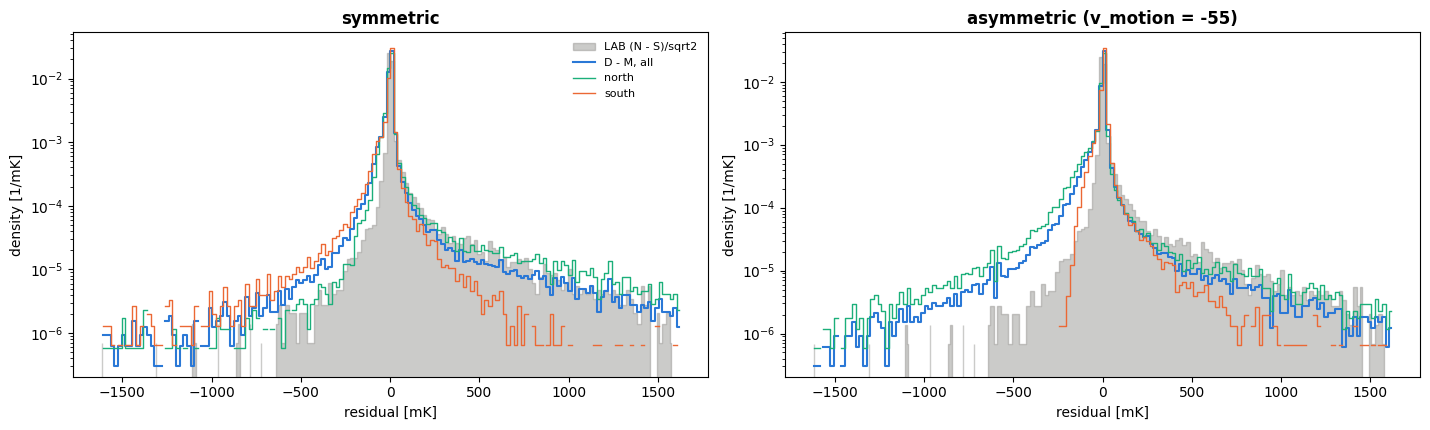

In [5]:
CUBES = {}
for lab_, (nm, folder) in MODELS.items():
    f = Path(folder) / f"{nm}.npz"
    if not f.exists():
        print(f"{lab_}: {f} not found, skipped")
        continue
    cube, l_, b_, v_ = load_npz(f)
    mod = cmp.model_cmp(cube, (l_, b_, v_))
    M0 = np.asarray(mod.data, float)
    M0 = np.where(np.isfinite(D3), M0, np.nan)          # The voxels where data and model are valid.
    w3 = np.broadcast_to(np.cos(np.deg2rad(bgrid))[None, :, None], D3.shape)
    ok = np.isfinite(M0)
    scale = float((w3[ok] * D3[ok]).sum() / (w3[ok] * M0[ok]).sum())
    CUBES[lab_] = dict(M=scale * M0, R=D3 - scale * M0, scale=scale)
    print(f"{lab_:42s} {nm}: scale {scale:.4f}, {int(ok.sum())} valid voxels")

# The pairs valid in data AND model on both sides, per model.
PP, ROWS2 = {}, {}
for lab_, C in CUBES.items():
    RN, RS = C["R"][:, iN, :], C["R"][:, iS, :]
    PP[lab_] = np.isfinite(RN) & np.isfinite(RS)
    r_all = C["R"][np.isfinite(C["R"])] * 1e3
    r_n   = RN[np.isfinite(RN)] * 1e3
    r_s   = RS[np.isfinite(RS)] * 1e3
    rows = [("D - M, all valid voxels", describe(r_all)), 
            ("D - M, north", describe(r_n)), 
            ("D - M, south", describe(r_s)),
            ("D - M, voxels of the pairs (N and S together)", describe(np.concatenate([RN[PP[lab_]], RS[PP[lab_]]]) * 1e3)),
            ("(D_N - D_S)/sqrt2, the same pairs", describe((DN - DS)[PP[lab_]] * 1e3 / np.sqrt(2.0)))]
    ROWS2[lab_] = rows
    print(f"\n{lab_.capitalize()} (pairs valid in data and model: {int(PP[lab_].sum())})")
    show_table(rows)

fig, axs = plt.subplots(1, len(CUBES), figsize=(7.2 * len(CUBES), 4.4), squeeze=False)
X = float(np.percentile(np.abs(NS / np.sqrt(2.0)), 99.9)) * 1.3
bins = np.linspace(-X, X, 161)
xx = 0.5 * (bins[1:] + bins[:-1])
def dens(x): return np.histogram(x, bins=bins, density=True)[0]

for ax, (lab_, C) in zip(axs[0], CUBES.items()):
    RN, RS = C["R"][:, iN, :], C["R"][:, iS, :]
    ref = dens(NS / np.sqrt(2.0))
    ax.fill_between(xx, np.where(ref > 0, ref, np.nan), step="mid", color="#8d8c88", alpha=0.45, label="LAB (N - S)/sqrt2")
    for x, col, nm_ in ((C["R"][np.isfinite(C["R"])], "#2a78d6", "D - M, all"), 
                        (RN[np.isfinite(RN)], "#1baf7a", "north"), 
                        (RS[np.isfinite(RS)], "#eb6834", "south")):
        
        h = dens(x * 1e3)
        ax.step(xx, np.where(h > 0, h, np.nan), where="mid", color=col, lw=1.5 if nm_ == "D - M, all" else 1.0, label=nm_)

    ax.set_yscale("log")
    ax.set_ylim(bottom=0.3 / (NS.size * (bins[1] - bins[0])))
    ax.set(xlabel="residual [mK]", ylabel="density [1/mK]")
    ax.set_title(lab_, weight="bold")
axs[0, 0].legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(PLOT / "residual_DM_hist.png", dpi=150)
plt.show()

### 2.2 Common and antisymmetric parts of the residual

On the pairs, the residual of each voxel is $r_N = D_N - M_N$, $r_S = D_S - M_S$. With $r_{\rm sym} = (r_N + r_S)/2$ and $r_{\rm anti} = (r_N - r_S)/2$ the variance splits,
$$\mathrm{var}(r_N) + \mathrm{var}(r_S) = 2\,\mathrm{var}(r_{\rm sym}) + 2\,\mathrm{var}(r_{\rm anti}),$$
and two per-voxel scales are defined, $s_{\rm sym} = \sqrt 2\,\mathrm{sd}(r_{\rm sym})$ and $s_{\rm anti} = \sqrt 2\,\mathrm{sd}(r_{\rm anti}) = \mathrm{sd}(r_N - r_S)/\sqrt 2$. For independent hemispheres around a perfect axisymmetric model both equal the scatter $s$ of one voxel.

- $s_{\rm anti}$ of a **symmetric** model is $s_{NS} = \mathrm{sd}(D_N - D_S)/\sqrt 2$ of section 1 (up to the effect of the one-sided masks on the smoothed model): no axisymmetric model can go below it. An **asymmetric** model has $r_N - r_S = (D_N - D_S) - (M_N - M_S)$, and the share of the N-S variance it explains is $1 - s_{\rm anti}^2 / s_{NS}^2$.
- $s_{\rm sym}$ is the misfit of what the two hemispheres have in common (the shape of the model in $l$, $|b|$, $v$, its amplitude). 
    * $s_{\rm sym} > s_{\rm anti}$ means that the model can still be improved symmetrically.
    * $s_{\rm sym} \approx s_{\rm anti}$ means that the remaining residual is as large as the difference between the two sides of the sky itself.
- $\rho = \mathrm{corr}(r_N, r_S) = (s_{\rm sym}^2 - s_{\rm anti}^2)/(s_{\rm sym}^2 + s_{\rm anti}^2)$.

Rms and robust (MAD) widths are given; they differ if the tails are heavy.

In [6]:
def rob_sd(x): 
    x = np.asarray(x, float)
    return 1.4826 * float(np.median(np.abs(x - np.median(x))))

SPLIT = {}
for lab_, C in CUBES.items():
    q = PP[lab_]
    rN, rS = C["R"][:, iN, :][q] * 1e3, C["R"][:, iS, :][q] * 1e3
    rsym, ranti = 0.5 * (rN + rS), 0.5 * (rN - rS)
    d = dict(n=int(q.sum()),
             s_res_rms=float(np.sqrt(0.5 * (np.mean(rN ** 2) + np.mean(rS ** 2)))), 
             s_res_rob=0.5 * (rob_sd(rN) + rob_sd(rS)),
             s_sym_rms=float(np.sqrt(2.0) * np.sqrt(np.mean(rsym ** 2))), 
             s_sym_rob=float(np.sqrt(2.0) * rob_sd(rsym)),
             s_anti_rms=float(np.sqrt(2.0) * np.sqrt(np.mean(ranti ** 2))), 
             s_anti_rob=float(np.sqrt(2.0) * rob_sd(ranti)),
             s_NS_rms=float(np.sqrt(np.mean(((DN - DS)[q] * 1e3) ** 2) / 2.0)), 
             s_NS_rob=float(rob_sd((DN - DS)[q] * 1e3) / np.sqrt(2.0)),
             rho=float(np.corrcoef(rN, rS)[0, 1]))
    
    d["explained_rms"] = 1.0 - d["s_anti_rms"] ** 2 / d["s_NS_rms"] ** 2
    d["explained_rob"] = 1.0 - d["s_anti_rob"] ** 2 / d["s_NS_rob"] ** 2
    SPLIT[lab_] = d

print(f"All widths in mK, on the pairs valid in data and model; noise of one voxel {1e3 * SIGMA:.1f} mK\n")
print(f"{'':42s} {'pairs':>7s} | {'sd(D-M)':>8s} {'s_sym':>7s} {'s_anti':>7s} {'s_NS':>7s} | "
      f"{'rho':>6s} {'N-S variance explained':>23s}")
for kind in ("rms", "rob"):
    print(f"> [{kind}]")
    for lab_, d in SPLIT.items():
        print(f"{lab_:42s} {d['n']:7d} | {d['s_res_' + kind]:8.1f} {d['s_sym_' + kind]:7.1f} "
              f"{d['s_anti_' + kind]:7.1f} {d['s_NS_' + kind]:7.1f} | {d['rho']:6.2f} {100 * d['explained_' + kind]:22.1f}%")

All widths in mK, on the pairs valid in data and model; noise of one voxel 3.1 mK

                                             pairs |  sd(D-M)   s_sym  s_anti    s_NS |    rho  N-S variance explained
> [rms]
symmetric                                    71572 |    128.3   155.3    93.6    93.6 |   0.53                    0.0%
asymmetric (v_motion = -55)                  71572 |     95.7   100.2    90.9    93.6 |   0.15                    5.7%
> [rob]
symmetric                                    71572 |      7.6     8.9     5.2     5.2 |   0.53                   -0.3%
asymmetric (v_motion = -55)                  71572 |      7.3     8.8     5.8     5.2 |   0.15                  -24.1%


### 2.3 The brightness law of $D - M$, against the one of $N - S$

The same binning as in section 1.1, but by the **model** brightness $M$ (as the likelihood uses it), and the width of $D - M$ itself. The orange curve is the law fitted to $N - S$ (a model-free estimate of the scatter around a common sky). The gray dotted one is the `huber_sc` default from previous notebooks ($\sigma_0 = 12$ mK, $\epsilon = 1$).

symmetric                                  rms law: sigma0 =  11.8 mK, eps = 1.135;   robust law: sigma0 =   5.5 mK, eps = 0.352
asymmetric (v_motion = -55)                rms law: sigma0 =  14.0 mK, eps = 0.996;   robust law: sigma0 =   5.5 mK, eps = 0.342
LAB (N - S)/sqrt2, by the mean of the pair rms law: sigma0 =   3.7 mK, eps = 0.405;   robust law: sigma0 =   3.5 mK, eps = 0.325


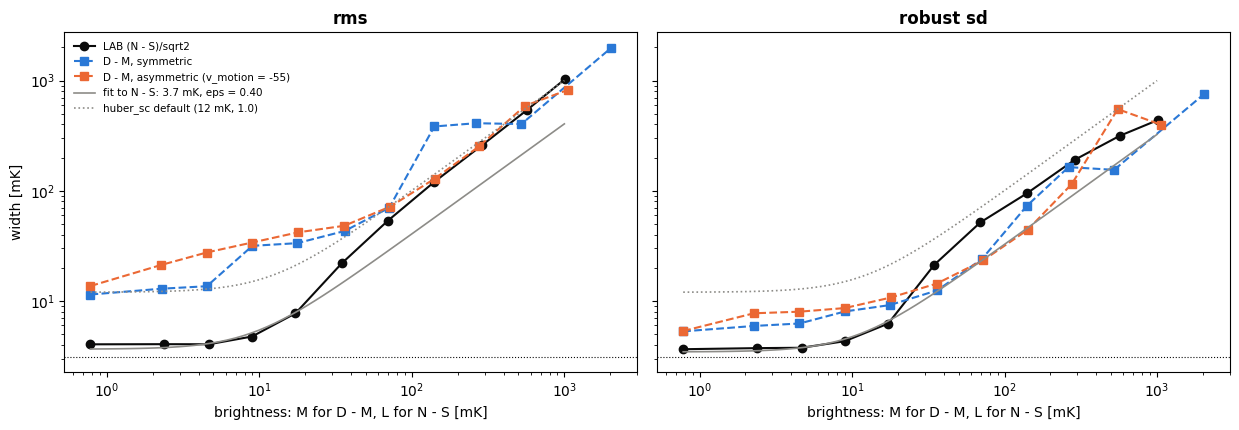

In [7]:
LAW_DM, ROWS_DM = {}, {}
for lab_, C in CUBES.items():
    ok = np.isfinite(C["R"])
    m_ = C["M"][ok]
    r_ = C["R"][ok]
    rows = level_rows(np.clip(m_, 0.0, None), r_, EDGES)
    ROWS_DM[lab_] = rows
    LAW_DM[lab_] = {k: fit_law(rows, k) for k in ("rms", "rob")}
    print(f"{lab_:42s} rms law: sigma0 = {1e3 * LAW_DM[lab_]['rms'][0]:5.1f} mK, "
          f"eps = {LAW_DM[lab_]['rms'][1]:.3f};   robust law: sigma0 = {1e3 * LAW_DM[lab_]['rob'][0]:5.1f} mK, "
          f"eps = {LAW_DM[lab_]['rob'][1]:.3f}")
print(f"{'LAB (N - S)/sqrt2, by the mean of the pair':42s} rms law: sigma0 = {1e3 * LAW_NS['rms'][0]:5.1f} mK, "
      f"eps = {LAW_NS['rms'][1]:.3f};   robust law: sigma0 = {1e3 * LAW_NS['rob'][0]:5.1f} mK, eps = {LAW_NS['rob'][1]:.3f}")

cols = ["#2a78d6", "#eb6834"]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, key, ttl in ((axs[0], "rms", "rms"), (axs[1], "rob", "robust sd")):
    ax.loglog([1e3 * max(r["m"], 0.25 * SIGMA) for r in ROWS_NS], 
              [1e3 * r[key] for r in ROWS_NS], "o-", color="#0b0b0b", label="LAB (N - S)/sqrt2")
    
    for (lab_, rows), col in zip(ROWS_DM.items(), cols):
        ax.loglog([1e3 * max(r["m"], 0.25 * SIGMA) for r in rows], 
                  [1e3 * r[key] for r in rows], "s--", color=col, label=f"D - M, {lab_}")
    
    mg = np.geomspace(0.25 * SIGMA, 1.0, 60); a0, eps = LAW_NS[key]
    ax.loglog(1e3 * mg, 1e3 * np.sqrt(a0 ** 2 + (eps * mg) ** 2), "-", 
              color="#8d8c88", lw=1.2, label=f"fit to N - S: {1e3 * a0:.1f} mK, eps = {eps:.2f}")
    ax.loglog(1e3 * mg, 1e3 * np.sqrt(0.012 ** 2 + (1.0 * mg) ** 2), ":", 
              color="#8d8c88", lw=1.2, label="huber_sc default (12 mK, 1.0)")
    ax.axhline(1e3 * SIGMA, color="#0b0b0b", ls=":", lw=0.8)
    ax.set_xlabel("brightness: M for D - M, L for N - S [mK]")
    ax.set_title(ttl, weight="bold")

axs[0].set_ylabel("width [mK]")
axs[0].legend(frameon=False, fontsize=7.5)

plt.tight_layout()
plt.savefig(PLOT / "residual_law.png", dpi=150)
plt.show()

## 3. What $\sigma$ to expect

The numbers side by side: the instrument noise, the model-free scatter of LAB around a common sky ($s_{NS}$), and the width of the residual of each model, in the two forms in which a Bayesian step can use them (a constant $\sigma$, and $\sigma_0$, $\epsilon$ of $\sigma^2 = \sigma_0^2 + \epsilon^2 M^2$).

(A constant $\sigma$ is a compromise: the width grows with brightness, so the faint voxels, which carry most of the weight in the likelihood, want the small $\sigma_0$ and the bright ones the large $\epsilon M$. Heavy tails argue for a Student-$t$ or a Huber core with the *robust* width, with the rms telling by how much the tails inflate the Gaussian one.)

In [8]:
SUMMARY = dict(sigma_noise_mK=1e3 * SIGMA, 
               LAB_NS=dict(pairs=int(PAIR.sum()), **{k: v for k, v in dNS.items() if k != "n"}, student_nu=float(nu_t),
               s_NS_rms_mK=dNS["sd"] / np.sqrt(2.0), s_NS_rob_mK=dNS["rob"] / np.sqrt(2.0),
               law_rms=dict(sigma0_mK=1e3 * LAW_NS["rms"][0], eps=LAW_NS["rms"][1]), 
               law_rob=dict(sigma0_mK=1e3 * LAW_NS["rob"][0], eps=LAW_NS["rob"][1])),
               models={})

for lab_ in CUBES:
    SUMMARY["models"][lab_] = dict(scale=CUBES[lab_]["scale"], **SPLIT[lab_],
                                   law_rms=dict(sigma0_mK=1e3 * LAW_DM[lab_]["rms"][0], eps=LAW_DM[lab_]["rms"][1]),
                                   law_rob=dict(sigma0_mK=1e3 * LAW_DM[lab_]["rob"][0], eps=LAW_DM[lab_]["rob"][1]))

print(f"{'':44s} {'constant sigma (mK)':>22s}  {'sigma_0 (mK), eps':>20s}")
print(f"{'instrument noise of one voxel':44s} {1e3 * SIGMA:12.1f} {'':>9s}  {'':>20s}")
print(f"{'LAB (N - S)/sqrt2: rms | robust':44s} {dNS['sd'] / np.sqrt(2):12.1f} | "
      f"{dNS['rob'] / np.sqrt(2):<7.1f}  rob: {1e3 * LAW_NS['rob'][0]:5.1f}, {LAW_NS['rob'][1]:.2f}")

for lab_ in CUBES:
    d = SPLIT[lab_]
    print(f"{'D - M, ' + lab_:44s} {d['s_res_rms']:12.1f} | {d['s_res_rob']:<7.1f}  "
          f"rob: {1e3 * LAW_DM[lab_]['rob'][0]:5.1f}, {LAW_DM[lab_]['rob'][1]:.2f}")
print("\n(rms | robust, on the pairs; the last column is the robust brightness law)")

                                                constant sigma (mK)     sigma_0 (mK), eps
instrument noise of one voxel                         3.1                                
LAB (N - S)/sqrt2: rms | robust                      93.0 | 5.2      rob:   3.5, 0.32
D - M, symmetric                                    128.3 | 7.6      rob:   5.5, 0.35
D - M, asymmetric (v_motion = -55)                   95.7 | 7.3      rob:   5.5, 0.34

(rms | robust, on the pairs; the last column is the robust brightness law)


## 4. Further checks: what the widths are made of

From sections 1-3, we see that LAB shows a core and very extended wings in $N - S$ (robust width a few mK, rms about thirty times the noise), a width that grows with brightness, and a hemisphere-by-hemisphere residual with a positive median.

1. $D - M$ was binned by the model brightness $M$ and $N - S$ by the pair mean $L$ of the data: not like for like. Here both are binned by $L$, and the ratio $s_{\rm res}/s_{NS}$ and the split $s_{\rm sym}$, $s_{\rm anti}$ are given per brightness bin.
2. the tails after the width has been divided out (a mixture of widths looks like a $t$ with $\nu \approx 1$, which says little about the noise).
3. the estimator of Marasco+19 (HALOGAS) for the width of their likelihood: $\epsilon = \sigma_{\delta I}\, n_{\rm vpr}$ with $\delta I = I(i,j,k) - I(-i,-j,-k)$, here with $\delta I = D_N - D_S$.


Symmetric (widths in mK, pairs valid in data and model, binned by the pair mean L of the data)
       L   pairs | s_NS rob s_res rob  ratio  s_sym s_anti | s_NS rms s_res rms  ratio
     0.4    9511 |      3.7       3.4   0.93    2.7    3.6 |      4.0       5.9   1.47
     2.4    6351 |      3.7       3.3   0.87    1.2    3.7 |      4.1       7.8   1.93
     4.7   14440 |      3.8       3.5   0.93    2.1    3.8 |      4.0       8.1   1.99
     8.9   16885 |      4.3       5.2   1.20    5.1    4.3 |      4.8      23.3   4.89
    17.2   13757 |      6.2      13.2   2.13   15.9    6.3 |      7.7      36.4   4.71
    34.6    4667 |     21.3      42.1   1.98   54.3   21.4 |     21.9      65.3   2.98
    69.4    2613 |     51.6      70.1   1.36   76.5   51.3 |     53.4      85.8   1.61
   139.7    1420 |     95.6     128.2   1.34   97.6   95.9 |    119.9     134.8   1.12
   288.0     848 |    191.1     257.2   1.35  132.5  191.8 |    258.6     398.3   1.54
   567.7     802 |    304.1     48

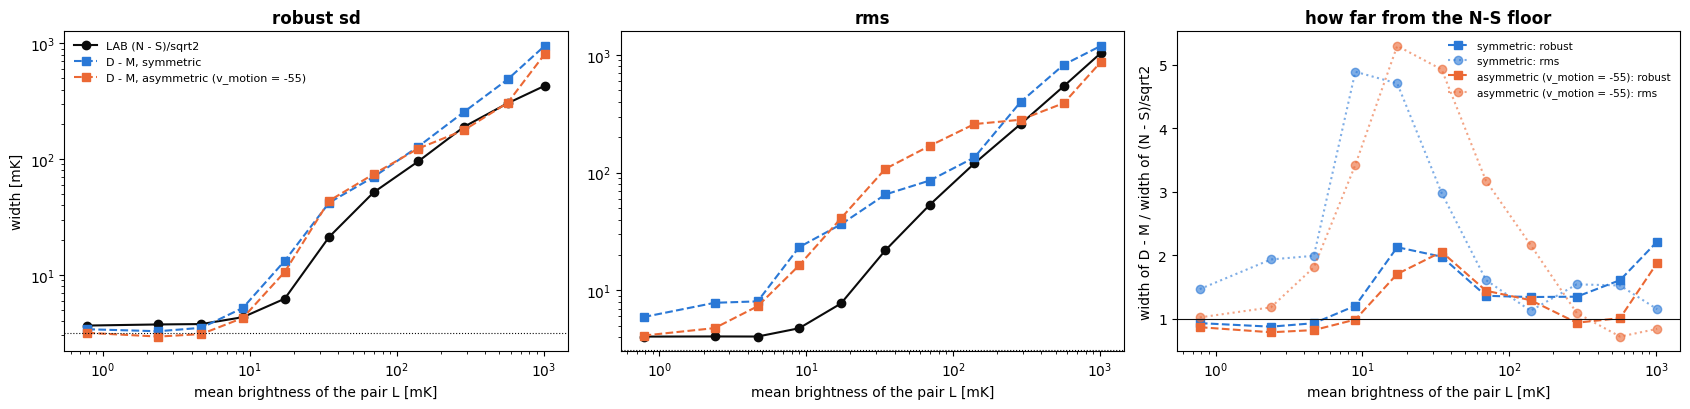

In [9]:
# ---- 4.1 like for like: everything binned by the pair mean L of the data
def bin_widths(level, x, edges, min_n=30):
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        q = (level >= lo) & (level < hi)
        if q.sum() < min_n:
            continue
        xx = x[q]
        out.append(dict(m=float(level[q].mean()), 
                        n=int(q.sum()), 
                        rms=float(np.sqrt(np.mean(xx ** 2))), 
                        rob=float(rob_sd(xx))))
    return out

LIKE = {}
for lab_, C in CUBES.items():
    q = PP[lab_]
    Lq = np.clip(0.5 * (DN + DS)[q], 0.0, None)
    rN, rS = C["R"][:, iN, :][q], C["R"][:, iS, :][q]
    ns = (DN - DS)[q] / np.sqrt(2.0)
    LIKE[lab_] = dict(ns=bin_widths(Lq, ns, EDGES), 
                      res=bin_widths(np.concatenate([Lq, Lq]), np.concatenate([rN, rS]), EDGES, min_n=60),
                      sym=bin_widths(Lq, np.sqrt(2.0) * 0.5 * (rN + rS), EDGES), 
                      anti=bin_widths(Lq, np.sqrt(2.0) * 0.5 * (rN - rS), EDGES))
    
    print(f"\n{lab_.capitalize()} (widths in mK, pairs valid in data and model, binned by the pair mean L of the data)")
    print(f"{'L':>8s} {'pairs':>7s} | {'s_NS rob':>8s} {'s_res rob':>9s} {'ratio':>6s} {'s_sym':>6s} {'s_anti':>6s} | "
          f"{'s_NS rms':>8s} {'s_res rms':>9s} {'ratio':>6s}")
    for a, b_, c, d, e in zip(LIKE[lab_]["ns"], LIKE[lab_]["res"], LIKE[lab_]["sym"], LIKE[lab_]["anti"], range(99)):
        print(f"{1e3 * a['m']:8.1f} {a['n']:7d} | {1e3 * a['rob']:8.1f} {1e3 * b_['rob']:9.1f} {b_['rob'] / a['rob']:6.2f} "
              f"{1e3 * c['rob']:6.1f} {1e3 * d['rob']:6.1f} | {1e3 * a['rms']:8.1f} {1e3 * b_['rms']:9.1f} "
              f"{b_['rms'] / a['rms']:6.2f}")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
ref = next(iter(LIKE.values()))["ns"]; xm = [1e3 * max(r["m"], 0.25 * SIGMA) for r in ref]

for ax, key, ttl in ((axs[0], "rob", "robust sd"), (axs[1], "rms", "rms")):
    ax.loglog(xm, [1e3 * r[key] for r in ref], "o-", color="#0b0b0b", label="LAB (N - S)/sqrt2")

    for (lab_, d), col in zip(LIKE.items(), cols):
        ax.loglog([1e3 * max(r["m"], 0.25 * SIGMA) for r in d["res"]], 
                  [1e3 * r[key] for r in d["res"]], "s--", color=col, label=f"D - M, {lab_}")
    ax.axhline(1e3 * SIGMA, color="#0b0b0b", ls=":", lw=0.8)
    ax.set_xlabel("mean brightness of the pair L [mK]")
    ax.set_title(ttl, weight="bold")
axs[0].set_ylabel("width [mK]")
axs[0].legend(frameon=False, fontsize=8)

for (lab_, d), col in zip(LIKE.items(), cols):
    axs[2].semilogx([1e3 * max(r["m"], 0.25 * SIGMA) for r in d["res"]], 
                    [b_["rob"] / a["rob"] for a, b_ in zip(d["ns"], d["res"])], "s--", 
                    color=col, label=f"{lab_}: robust")
    axs[2].semilogx([1e3 * max(r["m"], 0.25 * SIGMA) for r in d["res"]], 
                    [b_["rms"] / a["rms"] for a, b_ in zip(d["ns"], d["res"])], "o:", 
                    color=col, alpha=0.6, label=f"{lab_}: rms")
    
axs[2].axhline(1.0, color="#0b0b0b", lw=0.8)
axs[2].set(xlabel="mean brightness of the pair L [mK]", ylabel="width of D - M / width of (N - S)/sqrt2")
axs[2].set_title("how far from the N-S floor", weight="bold")
axs[2].legend(frameon=False, fontsize=7.5)

plt.tight_layout()
plt.savefig(PLOT / "residual_like_for_like.png", dpi=150)
plt.show()

z = residual / (robust width of its brightness bin): tails of what is left (|z - median| beyond k (def. 1.5); Gaussian in the last row)

                                                          n  ex.kurt     >1.5       >3        >4         >5   t: nu
LAB N - S, in bins of L                               71680      0.7   16.67%    0.91%    0.134%    0.0335%   16.95
D - M, symmetric, in bins of M                       160304    166.3   30.02%    5.64%    3.234%    2.3692%    2.79
D - M, asymmetric (v_motion = -55), in bins of M     160304    321.8   27.67%    7.28%    2.292%    1.6656%    2.77
Gaussian                                                         0.0   13.36%    0.27%    0.006%    0.0001%


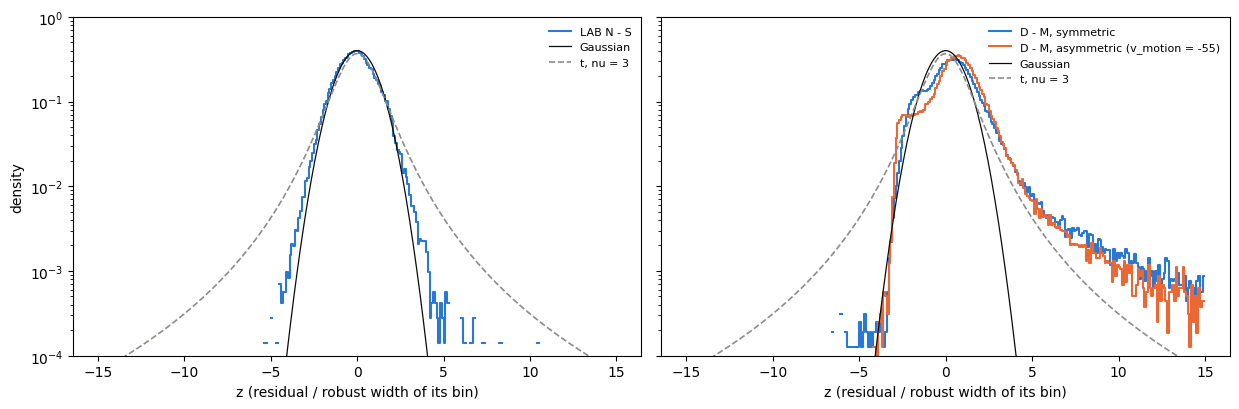

In [10]:
# ---- 4.2 tails after dividing out the width
def width_at(level, rows, key="rob"):
    mm = np.array([max(r["m"], 1e-6) for r in rows])
    ww = np.array([r[key] for r in rows])
    return np.exp(np.interp(np.log(np.clip(level, mm[0], None)), np.log(mm), np.log(ww)))

def tail_row(z):
    z = z[np.isfinite(z)]; med = np.median(z)
    d = dict(n=z.size, 
             kurt=float(stats.kurtosis(z)), 
             **{f"gt{k:g}": float(np.mean(np.abs(z - med) > k)) for k in (1.5, 3, 4, 5)})
    sub = z if z.size <= 40000 else np.random.default_rng(5).choice(z, 40000, replace=False)
    d["nu"] = float(stats.t.fit(sub)[0])
    return d

TAILS = {}
LEVq = np.clip(LEV, 0.0, None)
TAILS["LAB N - S, in bins of L"] = tail_row(S_NS / width_at(LEVq, ROWS_NS))
for lab_, C in CUBES.items():
    ok = np.isfinite(C["R"])
    m_ = np.clip(C["M"][ok], 0.0, None)
    TAILS[f"D - M, {lab_}, in bins of M"] = tail_row(C["R"][ok] / width_at(m_, ROWS_DM[lab_]))
gauss_ = {k: 2 * stats.norm.sf(k) for k in (1.5, 3, 4, 5)}
print("z = residual / (robust width of its brightness bin): tails of what is left "
      "(|z - median| beyond k (def. 1.5); Gaussian in the last row)\n")
print(f"{'':50s} {'n':>8s} {'ex.kurt':>8s} {'>1.5':>8s} {'>3':>8s} {'>4':>9s} {'>5':>10s} {'t: nu':>7s}")
for name, d in TAILS.items():
    print(f"{name:50s} {d['n']:8d} {d['kurt']:8.1f} {100 * d['gt1.5']:7.2f}% "
          f"{100 * d['gt3']:7.2f}% {100 * d['gt4']:8.3f}% {100 * d['gt5']:9.4f}% {d['nu']:7.2f}")

print(f"{'Gaussian':50s} {'':8s} {0.0:8.1f} {100 * gauss_[1.5]:7.2f}% {100 * gauss_[3]:7.2f}% "
      f"{100 * gauss_[4]:8.3f}% {100 * gauss_[5]:9.4f}%")

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
zs = {"LAB N - S": S_NS / width_at(LEVq, ROWS_NS)}
for lab_, C in CUBES.items():
    ok = np.isfinite(C["R"])
    zs[f"D - M, {lab_}"] = C["R"][ok] / width_at(np.clip(C["M"][ok], 0.0, None), ROWS_DM[lab_])

bins = np.linspace(-15, 15, 301); xx = 0.5 * (bins[1:] + bins[:-1])
for ax, names in ((axs[0], ["LAB N - S"]), (axs[1], [n for n in zs if n != "LAB N - S"])):
    for nm_, col in zip(names, cols if ax is axs[1] else ["#2a78d6"]):
        h = np.histogram(zs[nm_], bins=bins, density=True)[0]
        ax.step(xx, np.where(h > 0, h, np.nan), where="mid", color=col, label=nm_)

    ax.plot(xx, stats.norm.pdf(xx), "-", color="#0b0b0b", lw=0.9, label="Gaussian")
    ax.plot(xx, stats.t.pdf(xx, 3), "--", color="#8d8c88", lw=1.2, label="t, nu = 3")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.0)
    ax.set_xlabel("z (residual / robust width of its bin)")
    ax.legend(frameon=False, fontsize=8)
axs[0].set_ylabel("density")

plt.tight_layout()
plt.savefig(PLOT / "residual_standardized.png", dpi=150)
plt.show()

In [11]:
# ---- 4.5 the estimator of Marasco+19: sigma_dI of the reflection, times the voxels per resolution element
beam, pix = float(cmp.cfg.beam_fwhm), float(cmp.cfg.sampling)

# This is their Eq. 6 without the factor 2 for the Hanning smoothing in velocity.
nvpr2d = np.pi * beam * beam / (4.0 * np.log(2.0) * pix * pix)
print(f"Voxels per resolution element on the comparison grid: {nvpr2d:.1f} on the sky ({beam:g} deg beam, {pix:g} deg pixels); "
      f"\nx 2 if the channels are Hanning-correlated as in their data: {2 * nvpr2d:.1f}")

x_ = NS - np.median(NS)
cands = {"std of D_N - D_S (their sigma_dI)": float(np.std(NS)), 
         "std / sqrt2": float(np.std(NS) / np.sqrt(2.0)),
         "robust (MAD) sd of D_N - D_S": dNS["rob"], 
         "mean |D_N - D_S - median| (the Laplace scale of exp(-sum|r|/eps))": float(np.mean(np.abs(x_)))}

print(f"\n{'sigma_dI':65s} {'[mK]':>8s} {'x noise':>8s} {'eps = x n_vpr':>14s} {'(x 2 n_vpr)':>12s} (noise {1e3*SIGMA:.2f} mK)")
for k, v in cands.items():
    print(f"{k:65s} {v:8.1f} {v / (1e3 * SIGMA):8.1f} {v * nvpr2d:14.0f} {v * 2 * nvpr2d:12.0f}")
print("\nThey find sigma_dI = 1 to 8 x the noise and eps = 20 to 160 x the noise, with one constant eps for the whole cube "
      "\n(absolute-residual likelihood exp(-R/eps), R = sum |D - M|).")

Voxels per resolution element on the comparison grid: 4.5 on the sky (8 deg beam, 4 deg pixels); 
x 2 if the channels are Hanning-correlated as in their data: 9.1

sigma_dI                                                              [mK]  x noise  eps = x n_vpr  (x 2 n_vpr) (noise 3.12 mK)
std of D_N - D_S (their sigma_dI)                                    131.5     42.1            596         1192
std / sqrt2                                                           93.0     29.8            421          843
robust (MAD) sd of D_N - D_S                                           7.3      2.3             33           66
mean |D_N - D_S - median| (the Laplace scale of exp(-sum|r|/eps))     28.3      9.1            128          257

They find sigma_dI = 1 to 8 x the noise and eps = 20 to 160 x the noise, with one constant eps for the whole cube 
(absolute-residual likelihood exp(-R/eps), R = sum |D - M|).
